In [1]:
import numpy as np
import torch

import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../src_time")))

from autoencoder import SINDyConvAE
from training import train_sindy_convae, save_model_and_params
from sindy_utils import library_size

from example_dg import get_dg_data, get_dg_loaders


[INFO] Global seed set to 42 (PyTorch, NumPy, Random)


In [2]:
# physical parameters
amplitude = 0.25
frequency = 5.0     

# spatial discretization
nx = 64
ny = 32
Lx = 2.0
Ly = 1.0

# temporal discretization
dt = 0.05
T = 100.0

# Dataset creation
train_d, val_d, test_d = get_dg_data(randomized=False,
                                     amplitude=amplitude, frequency=frequency, 
                                     Lx=Lx, Ly=Ly, nx=nx, ny=ny,
                                     T=T, dt=dt)


In [3]:
# ConvAE+SINDy parameters
params={}

# CAE structure
params['input_shape'] = (nx, ny, 2)
params['filter_widths'] = [16, 32]

# SINDy latent library
params['latent_dim'] = 1
params['poly_order'] = 3
params['include_sine'] = True # -> for this problem means include cos(4.998 t)
params['library_dim'] = library_size(params['latent_dim'], params['poly_order'], params['include_sine'])

# Loss penalties
params['loss_weights'] = {
    'decoder': 1.0,                     # Ricostruzione x
    'sindy_x': 1e-3,                    # Ricostruzione dx (tramite la dinamica latente)
    'sindy_z': 1e-2,                    # Consistenza latente dz/dt = Theta * Xi
    'sindy_reg': 1e-6                   # Sparsità (L1) dei coefficienti SINDy
}

# Thresholding
params['sequential_thresholding'] = True
params['threshold_frequency'] = 100
params['coefficient_threshold'] = 1e-2

# Training
params['activation'] = 'tanh'
params['learning_rate'] = 1e-3
params['batch_size'] = 32
params['print_frequency'] = 20

params['max_epochs'] = 1001
params['refinement_epochs'] = 101


In [4]:
# Torch loaders
train_loader, val_loader, test_loader = get_dg_loaders(train_d, val_d, test_d, 
                                                       batch_size=params['batch_size'], 
                                                       channels_first=False,
                                                       train_shuffle=True,
                                                       include_time=True)

In [5]:
# Model
model = SINDyConvAE(params)

# Train of the model
history = train_sindy_convae(model, train_loader, val_loader, params)

# Save
save_model_and_params(model, params, folder_path="./saved", model_name="model_final")



[INFO] SINDy Autoencoder Configuration:
  > Decoder weight:  1.00e+00
  > SINDy x weight:  1.00e-03
  > SINDy z weight:  1.00e-02
  > SINDy Reg (L1):  1.00e-06
[INFO] Computation norms on validation set...
[INFO] Validation X norm (MSE baseline): 2.4992e-02
[INFO] Validation dX norm (MSE baseline): 1.1170e-01

--- PHASE 1: TRAINING ---
[TRAIN] Epoch    0
  Train Loss: 2.6972e-02 ( Dec: 2.58e-02 | dX: 1.15e-01 | dZ: 1.05e-01 | Reg: 5.29e-01 )
  Valid Loss: 1.4353e-02 ( Dec: 1.35e-02 | dX: 1.13e-01 | dZ: 7.70e-02 )
  >> RATIO: Decoder: 0.5389 | SINDy: 1.0154
[TRAIN] Epoch   20
  Train Loss: 1.8189e-04 ( Dec: 1.51e-04 | dX: 1.10e-02 | dZ: 1.96e-03 | Reg: 5.45e-01 )
  Valid Loss: 2.2535e-04 ( Dec: 1.53e-04 | dX: 1.10e-02 | dZ: 6.13e-03 )
  >> RATIO: Decoder: 0.0061 | SINDy: 0.0983
[TRAIN] Epoch   40
  Train Loss: 1.2870e-04 ( Dec: 1.04e-04 | dX: 8.68e-03 | dZ: 1.51e-03 | Reg: 5.36e-01 )
  Valid Loss: 1.5682e-04 ( Dec: 1.07e-04 | dX: 8.66e-03 | dZ: 4.11e-03 )
  >> RATIO: Decoder: 0.0043 | 

In [6]:
# Analisi dei risultati finali
with torch.no_grad():
    # .detach() rimuove il tensore dal grafo dei gradienti
    final_xi = (model.sindy_coeffs * model.sindy_mask).detach().cpu().numpy()

print("Xi final:")
print(np.round(final_xi, 4)) 

active_mask = np.abs(final_xi) > 0
print(f"Active coefficients: {np.sum(active_mask)}")

Xi final:
[[-0.0523]
 [-0.3106]
 [ 0.    ]
 [ 0.    ]
 [-0.6391]]
Active coefficients: 3


In [5]:
import torch
import pickle
import numpy as np

# 1. Carica i parametri della struttura (architettura)
with open('./saved/model_final_params.pkl', 'rb') as f:
    params = pickle.load(f)

# 2. Istanzia il modello
# Nota: Devi aver importato la classe SINDyAutoencoder definita nel tuo script
model = SINDyConvAE(params) 

# 3. Carica i pesi di PyTorch (Weights & Buffers)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.load_state_dict(torch.load('./saved/model_final.pth', map_location=device))
model.eval() # Imposta in modalità valutazione

# 4. Carica i coefficienti SINDy (la "fisica" scoperta)
final_xi = np.load('./saved/model_final_coefficients.npy')

print("Caricamento completato con successo!")
print(f"Forma dei coefficienti SINDy: {final_xi.shape}")

Caricamento completato con successo!
Forma dei coefficienti SINDy: (5, 1)


var:  0.090510674


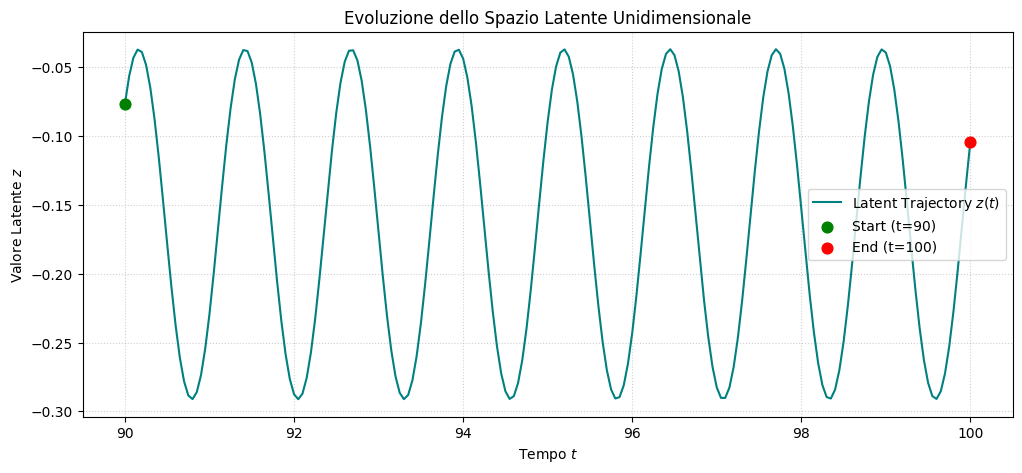

In [6]:
import torch
import numpy as np
import matplotlib.pyplot as plt

def plot_latent_evolution(model, test_loader, device='cuda'):
    model.eval()
    z_list = []
    
    # 1. Estrazione e Proiezione
    with torch.no_grad():
        for batch in test_loader:
            # Il loader restituisce (x, dx, t), prendiamo solo x
            x = batch[0].to(device)
            
            # Otteniamo la variabile latente (assicurati che il metodo sia .encode o .encoder)
            z = model.encode(x) 
            
            # Portiamo su CPU e convertiamo in numpy
            z_list.append(z.cpu().numpy())
    
    # Concateniamo tutti i batch in un unico vettore 1D
    z_test = np.concatenate(z_list).flatten()
    print("var: ",np.sqrt(np.var(z_test, ddof=1)))
    
    # 2. Creazione asse temporale (90, 100)
    # n_elem è automaticamente len(z_test)
    t_axis = np.linspace(90, 100, num=len(z_test))
    
    # 3. Visualizzazione
    plt.figure(figsize=(12, 5))
    plt.plot(t_axis, z_test, color='teal', linewidth=1.5, label='Latent Trajectory $z(t)$')
    
    # Marker per inizio e fine
    plt.scatter(t_axis[0], z_test[0], color='green', s=60, zorder=5, label='Start (t=90)')
    plt.scatter(t_axis[-1], z_test[-1], color='red', s=60, zorder=5, label='End (t=100)')
    
    plt.title('Evoluzione dello Spazio Latente Unidimensionale')
    plt.xlabel('Tempo $t$')
    plt.ylabel('Valore Latente $z$')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend()
    plt.show()

# --- ESECUZIONE ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

plot_latent_evolution(model, test_loader, device)

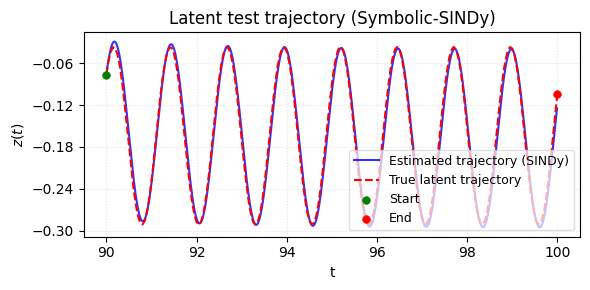

In [7]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from sindy_utils import sindy_simulate

def evaluate_and_plot_latent_1d(model, test_loader, Xi, poly_order, include_sine, device='cpu'):
    # =======================
    # STYLE CONFIGURATION
    # =======================
    plt.rcdefaults()
    
    model.eval()
    z_list = []
    
    # 1. Estrazione traiettoria reale (Baseline) dall'Encoder
    with torch.no_grad():
        for batch in test_loader:
            x = batch[0].to(device)
            z = model.encode(x)
            z_list.append(z.cpu().numpy())
    
    # Assicuriamo forma (N,) per il plot
    z_real = np.concatenate(z_list).flatten()
    n_samples = len(z_real)
    
    # 2. Generazione asse temporale (90-100)
    t_axis = np.linspace(90, 100, num=n_samples)
    
    # 3. Simulazione SINDy
    dt = 0.01
    t_sim = np.arange(90, 100, dt)
    z0 = np.array([z_real[0]]) # Punto iniziale
    
    # Simulazione tramite funzione esterna
    z_sindy = sindy_simulate(z0, t_sim, Xi, poly_order, include_sine)
    
    # =======================
    # PLOTTING
    # =======================
    fig, ax = plt.subplots(figsize=(6, 3)) 

    # Plot SINDy Prediction (Blue Solid)
    ax.plot(t_sim, z_sindy, 
            color='blue', alpha=0.8, lw=1.5, 
            label='Estimated trajectory (SINDy)', zorder=2)
    
    # Plot Baseline / True (Red Dashed)
    ax.plot(t_axis, z_real, linestyle='--',
            color='red', lw=1.5, 
            label='True latent trajectory', zorder=3)
    
    # Punti di controllo (Start / End)
    ax.scatter(t_axis[0], z_real[0], 
               color='green', s=30, linewidths=0.5,
               zorder=3, label='Start')
    ax.scatter(t_axis[-1], z_real[-1], 
               color='red', s=30, linewidths=0.5,
               zorder=3, label='End')
    
    # --- GESTIONE TICK ASSE Y ---
    # nbins=5 e prune='both' per alleggerire la densità dei numeri
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5, prune='both')) 
    
    # Estetica assi e titoli
    ax.set_title('Latent test trajectory (Symbolic-SINDy)', fontsize=12)
    ax.set_xlabel('t', fontsize=10)
    ax.set_ylabel('$z(t)$', fontsize=10)
    
    # Griglia debole puntinata
    ax.grid(True, linestyle=':', alpha=0.3)
    
    # =======================
    # LEGENDA SEMITRASPARENTE CON CONTORNO
    # =======================
    ax.legend(
        fontsize=9, 
        loc='lower right',
        frameon=True,          # Cornice attiva
        framealpha=0.7,        # Trasparenza sfondo
        facecolor='white',     # Sfondo bianco
        edgecolor='lightgray', # Contorno grigio chiaro (leggero)
        fancybox=True          # Angoli arrotondati
    )
    
    plt.tight_layout()
    plt.show()

# --- ESECUZIONE ---
evaluate_and_plot_latent_1d(
    model, 
    test_loader, 
    Xi=final_xi, 
    poly_order=params['poly_order'], 
    include_sine=params['include_sine'],
    device=device
)


--- Analysis for t = 94.50 (Index 90) ---
Component U: L1 Abs = 2.23667e-03, L1 Rel = 1.43%
Component V: L1 Abs = 3.08044e-03, L1 Rel = 1.91%
Grafico salvato: prediction_idx_90.png


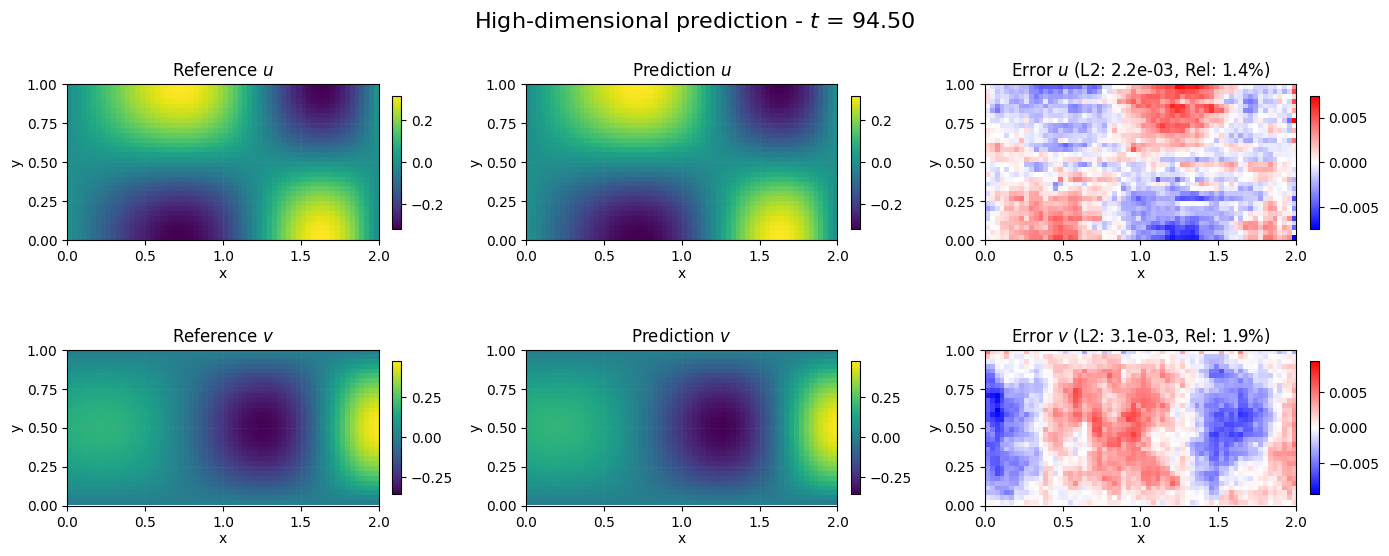


--- Analysis for t = 97.50 (Index 150) ---
Component U: L1 Abs = 1.00054e-02, L1 Rel = 6.34%
Component V: L1 Abs = 1.08397e-02, L1 Rel = 6.88%
Grafico salvato: prediction_idx_150.png


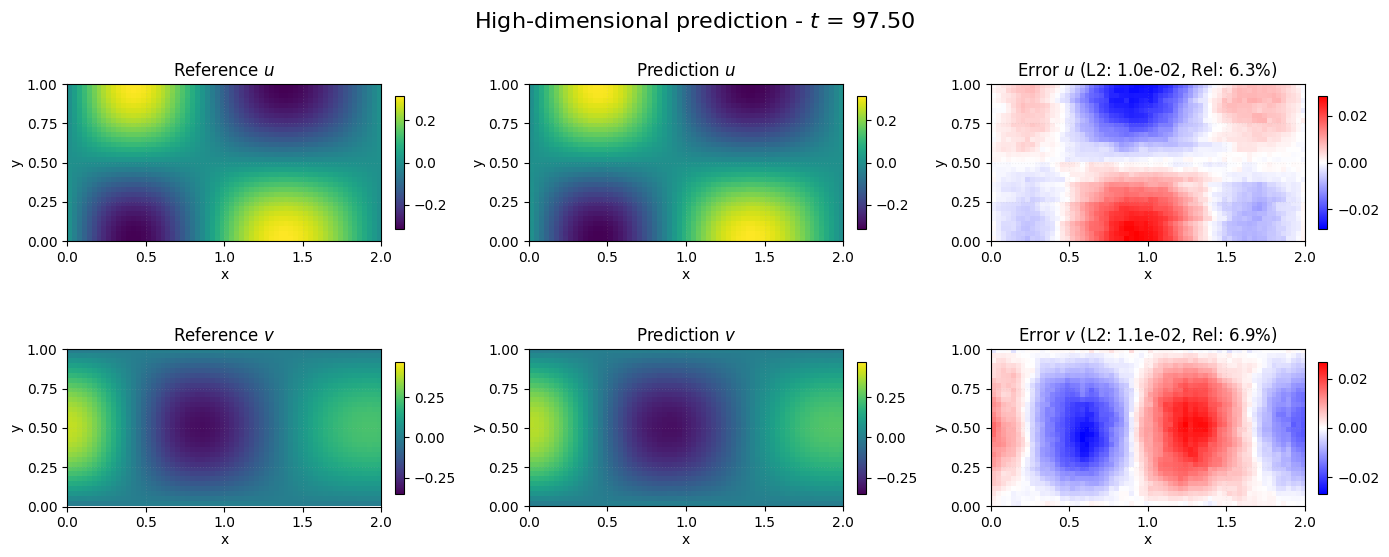


--- Analysis for t = 99.25 (Index 185) ---
Component U: L1 Abs = 5.57407e-03, L1 Rel = 3.52%
Component V: L1 Abs = 6.71111e-03, L1 Rel = 4.30%
Grafico salvato: prediction_idx_185.png


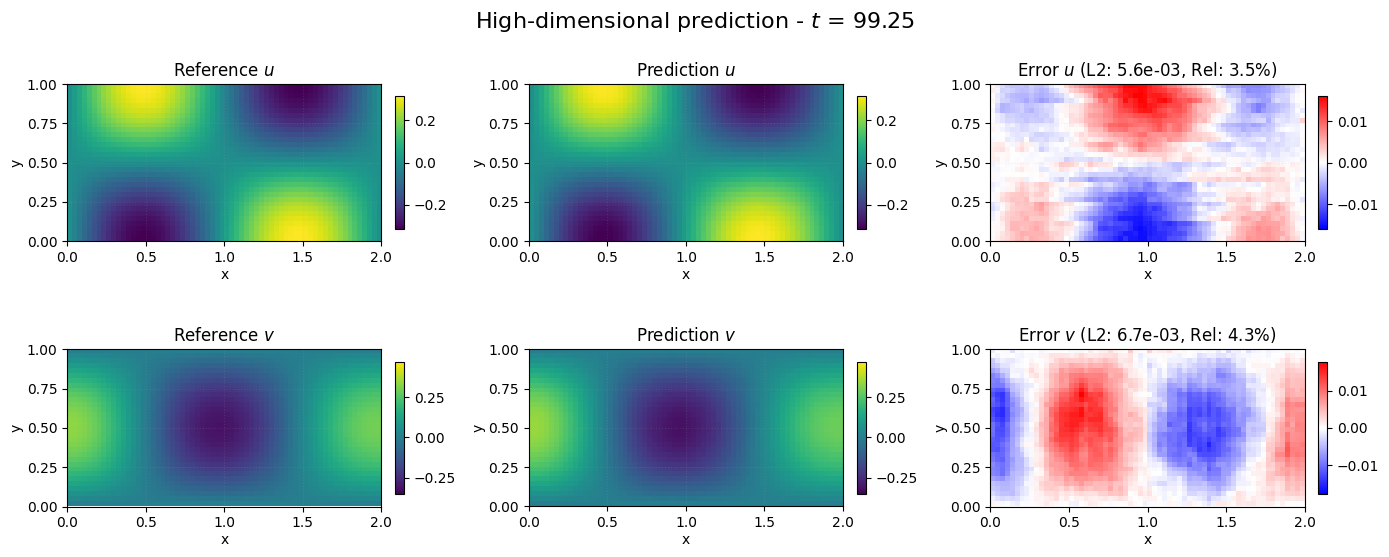

In [6]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from matplotlib.ticker import MaxNLocator
from matplotlib.colors import LinearSegmentedColormap
import os

def validate_rom_from_test_loader(model, test_loader, target_indices=None, num_frames_to_show=None, save_path=None):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.eval()

    # --- Definizione Colormap Custom (Blue-White-Red) ---
    custom_rwb = LinearSegmentedColormap.from_list("custom_rwb", ["blue", "white", "red"])

    # --- 1. RECUPERO DATI DAL TEST_LOADER ---
    all_x_true = []
    all_t_true = []
    
    with torch.no_grad():
        for batch in test_loader:
            x, _, t = batch  
            all_x_true.append(x.cpu())
            all_t_true.append(t.cpu())
            
    all_x_true = torch.cat(all_x_true, dim=0) 
    all_t_true = torch.cat(all_t_true, dim=0).numpy()
    n_samples = all_x_true.shape[0]

    # --- 2. GESTIONE INDICI ---
    if target_indices is not None:
        indices = [target_indices] if isinstance(target_indices, int) else target_indices
    elif num_frames_to_show is not None:
        indices = np.linspace(0, n_samples - 1, num_frames_to_show, dtype=int)
    else:
        indices = np.linspace(0, n_samples - 1, 3, dtype=int)

    # --- 3. CONDIZIONE INIZIALE E SIMULAZIONE SINDY ---
    x0 = all_x_true[0:1].to(device) 
    with torch.no_grad():
        z0 = model.encode(x0).cpu().numpy().flatten()

    def sindy_dynamics_ode(z_vec, t_val):
        z_tensor = torch.tensor(z_vec.reshape(1, -1), dtype=torch.float32).to(device)
        t_tensor = torch.tensor([t_val], dtype=torch.float32).to(device)
        with torch.no_grad():
            try:
                theta = model.construct_sindy_library(z_tensor, t_tensor)
            except TypeError:
                theta = model.construct_sindy_library(z_tensor)
                
            xi_eff = model.sindy_coeffs * model.sindy_mask
            dzdt = torch.matmul(theta, xi_eff)
        return dzdt.cpu().numpy().flatten()

    z_simulated = odeint(sindy_dynamics_ode, z0, all_t_true)

    # --- 4. DECODIFICA ---
    with torch.no_grad():
        z_sim_tensor = torch.tensor(z_simulated, dtype=torch.float32).to(device)
        x_sim_reconstructed = model.decode(z_sim_tensor).cpu().numpy()

    # --- 5. VISUALIZZAZIONE ---
    plot_extent = [0, 2, 0, 1]
    channel_names = ["u", "v"] # Per brevità nei log

    v_limits = []
    for c in range(2):
        v_limits.append({
            'min': all_x_true[..., c].min().item(),
            'max': all_x_true[..., c].max().item()
        })

    for idx in indices:
        if idx >= n_samples: continue

        print(f"\n--- Analysis for t = {all_t_true[idx]:.2f} (Index {idx}) ---")
        fig, axes = plt.subplots(2, 3, figsize=(14, 6))
        fig.suptitle(f"High-dimensional prediction - $t$ = {all_t_true[idx]:.2f}", 
                      fontsize=16, y=0.92)

        for c in range(2): 
            img_true = all_x_true[idx, ..., c].numpy().T
            img_sim  = x_sim_reconstructed[idx, ..., c].T
            residual = img_true - img_sim
            
            # --- CALCOLO ERRORI ---
            l2_abs = np.linalg.norm(residual) / np.sqrt(residual.size)
            l2_ref = np.linalg.norm(img_true) / np.sqrt(img_true.size)
            l2_rel_perc = (l2_abs / (l2_ref + 1e-12)) * 100
            
            # Stampa nel terminale
            print(f"Component {channel_names[c].upper()}: L1 Abs = {l2_abs:.5e}, L1 Rel = {l2_rel_perc:.2f}%")

            cbar_kwargs = {'fraction': 0.046, 'pad': 0.04, 'shrink': 0.6, 'aspect': 15}

            # --- Ground Truth ---
            im1 = axes[c, 0].imshow(img_true, cmap='viridis', origin='lower', 
                                    extent=plot_extent, vmin=v_limits[c]['min'], vmax=v_limits[c]['max'])
            axes[c, 0].set_title(f"Reference ${channel_names[c]}$", pad=6)
            plt.colorbar(im1, ax=axes[c, 0], **cbar_kwargs)

            # --- Prediction ---
            im2 = axes[c, 1].imshow(img_sim, cmap='viridis', origin='lower', 
                                    extent=plot_extent, vmin=v_limits[c]['min'], vmax=v_limits[c]['max'])
            axes[c, 1].set_title(f"Prediction ${channel_names[c]}$", pad=6)
            plt.colorbar(im2, ax=axes[c, 1], **cbar_kwargs)

            # --- Error (BWR centrato sullo zero) ---
            abs_err_max = max(np.max(np.abs(residual)), 1e-10)
            im3 = axes[c, 2].imshow(residual, cmap=custom_rwb, origin='lower', 
                                    extent=plot_extent, vmin=-abs_err_max, vmax=abs_err_max)
            
            # Titolo con doppia metrica: L1 e Relativa %
            axes[c, 2].set_title(f"Error ${channel_names[c]}$ (L2: {l2_abs:.1e}, Rel: {l2_rel_perc:.1f}%)", pad=6)
            plt.colorbar(im3, ax=axes[c, 2], **cbar_kwargs)

            for ax in axes[c]:
                ax.set_xlabel("x", labelpad=2); ax.set_ylabel("y", labelpad=2)
                ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
                ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
                ax.grid(alpha=0.15, linestyle=':')

        plt.tight_layout(rect=[0, 0, 1, 0.94])
        plt.subplots_adjust(hspace=0.2)

        if save_path:
            if not os.path.exists(save_path): os.makedirs(save_path)
            file_name = f"prediction_idx_{idx}.png"
            plt.savefig(os.path.join(save_path, file_name), dpi=300, bbox_inches='tight')
            print(f"Grafico salvato: {file_name}")

        plt.show()

# Esempio di utilizzo:
validate_rom_from_test_loader(model, test_loader, target_indices=[90,150,185], save_path='.')